# Doppio on AWS: Access Benchmarks

Companion to `doppio_aws_access.ipynb`. That notebook shows *how* to read the Doppio data on AWS; this one measures how read time grows with the length of the period requested, for two strategies:

- **NetCDF:** open the needed files with `xr.open_mfdataset`, then select
- **Zarr:** select from the Kerchunk reference file, which presents all files as one dataset

The request is a full-depth temperature **profile** time series at the NOPM grid cell, which is what a comparison with profiler data needs. A cheaper surface-point request is compared once at the end of the daily section.

Timings depend on your network and are single runs, so expect some noise. NetCDF time includes opening the files. For Zarr, the one-time cost of opening the reference file is reported separately. The longest windows are slow, so trim `windows` before running if you want a quick pass.

The AWS archive ends on 2024-12-30, so all windows must end before then.

In [1]:
import time

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import xarray as xr
from zarr.storage import FsspecStore

# OOI Pioneer Northern Offshore Profiler Mooring (NOPM)
nopm_lat, nopm_lon = 36.17983, -74.82667

BUCKET = "noaa-ioos-roms-doppio-v3-pds"
ARCHIVE_END = pd.Timestamp("2024-12-30")
s3 = s3fs.S3FileSystem(anon=True)

def open_nc(kind, n):
    """Open file number n of the 'avg' (daily) or 'his' (hourly) archive as a lazy file object."""
    name = f"doppio_avg_{n:04d}.nc" if kind == "avg" else f"doppio_fwd_{n:04d}_plusdye.nc"
    return s3.open(f"{BUCKET}/{kind}/{name}", mode="rb", cache_type="blockcache", block_size=4 * 2**20)

def file_numbers(start, end, kind="avg"):
    """Numbers of the files covering [start, end). Both archives hold 3 days per file, numbered
    from 366 = 2007-01-02. `his` files start at 01:00, hence the 1 hour shift."""
    first = np.datetime64("2007-01-02T00:00")
    shift = np.timedelta64(1, "h") if kind == "his" else np.timedelta64(0, "h")
    num = lambda t: int((t - shift - first) // np.timedelta64(3, "D")) * 3 + 366
    start, end = np.datetime64(start, "h"), np.datetime64(end, "h")
    return list(range(num(start), num(end - np.timedelta64(1, "h")) + 1, 3))

def open_zarr(url):
    fs = fsspec.filesystem(
        "reference", fo=url, remote_protocol="s3",
        remote_options={"anon": True, "asynchronous": True}, asynchronous=True,
    )
    return xr.open_dataset(FsspecStore(fs, read_only=True), engine="zarr", consolidated=False, chunks={})

# Nearest model grid cell to NOPM (the grid is the same in every file)
grid = xr.open_dataset(open_nc("avg", 366), engine="h5netcdf")
dist = (grid.lat_rho - nopm_lat) ** 2 + ((grid.lon_rho - nopm_lon) * np.cos(np.deg2rad(nopm_lat))) ** 2
j, i = np.unravel_index(np.argmin(dist.values), dist.shape)
print(f"Nearest cell: eta_rho={j}, xi_rho={i}")

Nearest cell: eta_rho=45, xi_rho=44


In [2]:
def run_benchmark(method, kind, start, end, task, zarr_ds=None):
    """Time one request. `end` is exclusive. task is 'profile' (all levels) or 'point' (surface)."""
    assert pd.Timestamp(end) <= ARCHIVE_END, f"{end} is after the end of the archive ({ARCHIVE_END.date()})"
    last = np.datetime64(end, "h") - np.timedelta64(1, "h")
    t0 = time.time()
    if method == "NetCDF":
        nums = file_numbers(start, end, kind)
        ds = xr.open_mfdataset(
            [open_nc(kind, n) for n in nums], engine="h5netcdf", combine="by_coords",
            data_vars="minimal", coords="minimal", compat="override",
        )
    else:
        nums, ds = [], zarr_ds
    t1 = time.time()
    sel = ds.temp.sel(ocean_time=slice(np.datetime64(start, "h"), last))
    sel = sel.isel(s_rho=-1, eta_rho=j, xi_rho=i) if task == "point" else sel.isel(eta_rho=j, xi_rho=i)
    out = sel.load()
    t2 = time.time()
    row = {
        "method": method, "task": task, "n_times": out.sizes["ocean_time"], "n_files": len(nums),
        "open_s": t1 - t0, "read_s": t2 - t1, "total_s": t2 - t0,
    }
    return row, out

## Daily means (`avg`): how does time grow with the window?

Each `avg` file holds 3 daily steps, chunked as 3 days x 1 level x the whole grid (0.3 MB). A full profile touches 40 chunks per file.

In [3]:
t0 = time.time()
zarr_avg = open_zarr(f"https://{BUCKET}.s3.amazonaws.com/avg/doppio_avg.zarr")
print(f"One-time cost of opening the avg Zarr reference: {time.time() - t0:.1f}s")

One-time cost of opening the avg Zarr reference: 5.1s


In [4]:
t_start = "2024-09-01"  # 3 months later is still inside the archive
windows = [
    ("1 day", pd.DateOffset(days=1)),
    ("1 week", pd.DateOffset(weeks=1)),
    ("2 weeks", pd.DateOffset(weeks=2)),
    ("1 month", pd.DateOffset(months=1)),
    ("3 months", pd.DateOffset(months=3)),
]

rows = []
for label, offset in windows:
    end = (pd.Timestamp(t_start) + offset).strftime("%Y-%m-%d")
    outs = {}
    for method in ("NetCDF", "Zarr"):
        row, outs[method] = run_benchmark(method, "avg", t_start, end, "profile", zarr_avg)
        rows.append({"window": label, **row})
        print(f"{label:9} {method:7} {row['total_s']:6.1f}s  ({row['n_times']} steps, {row['n_files']} files)")
    rows[-1]["identical"] = rows[-2]["identical"] = np.array_equal(outs["NetCDF"].values, outs["Zarr"].values)

bench = pd.DataFrame(rows)
bench

1 day     NetCDF     1.5s  (1 steps, 1 files)
1 day     Zarr       0.5s  (1 steps, 0 files)
1 week    NetCDF     4.6s  (7 steps, 3 files)
1 week    Zarr       0.8s  (7 steps, 0 files)
2 weeks   NetCDF     9.0s  (14 steps, 6 files)
2 weeks   Zarr       1.7s  (14 steps, 0 files)
1 month   NetCDF    16.7s  (30 steps, 11 files)
1 month   Zarr       2.9s  (30 steps, 0 files)
3 months  NetCDF    53.9s  (91 steps, 31 files)
3 months  Zarr       9.5s  (91 steps, 0 files)


,window,method,task,n_times,n_files,open_s,read_s,total_s,identical
0,1 day,NetCDF,profile,1,1,7.725477e-01,0.765547,1.538095,True
1,1 day,Zarr,profile,1,0,1.192093e-06,0.525230,0.525231,True
2,1 week,NetCDF,profile,7,3,2.198964e+00,2.391519,4.590483,True
3,1 week,Zarr,profile,7,0,9.536743e-07,0.793819,0.793820,True
4,2 weeks,NetCDF,profile,14,6,4.145903e+00,4.879449,9.025352,True
5,2 weeks,Zarr,profile,14,0,0.000000e+00,1.733483,1.733483,True
6,1 month,NetCDF,profile,30,11,9.082937e+00,7.652464,16.735401,True
7,1 month,Zarr,profile,30,0,0.000000e+00,2.895494,2.895494,True
8,3 months,NetCDF,profile,91,31,2.323519e+01,30.694869,53.930059,True
9,3 months,Zarr,profile,91,0,0.000000e+00,9.542088,9.542088,True


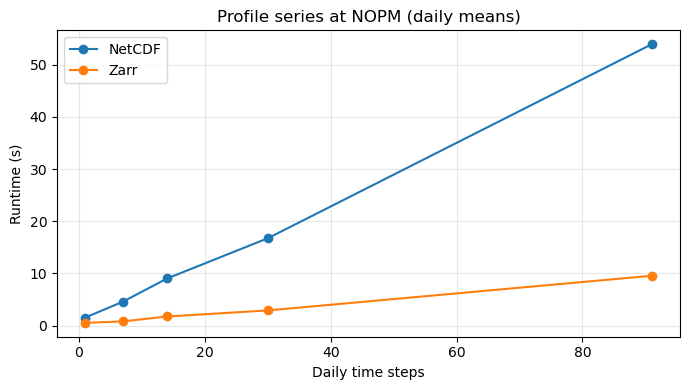

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in bench.groupby("method"):
    ax.plot(g["n_times"], g["total_s"], marker="o", label=method)
ax.set_xlabel("Daily time steps")
ax.set_ylabel("Runtime (s)")
ax.set_title("Profile series at NOPM (daily means)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Point vs profile

A surface point touches 1 chunk per file and a profile touches 40, so the two can differ a lot. Here is the 1 month window again with a surface point.

In [6]:
end_1m = (pd.Timestamp(t_start) + pd.DateOffset(months=1)).strftime("%Y-%m-%d")
rows_pt = []
for method in ("NetCDF", "Zarr"):
    row, _ = run_benchmark(method, "avg", t_start, end_1m, "point", zarr_avg)
    rows_pt.append(row)

point_vs_profile = pd.concat(
    [pd.DataFrame(rows_pt), bench[bench["window"] == "1 month"].drop(columns=["window", "identical"])]
)
point_vs_profile.round(1)

,method,task,n_times,n_files,open_s,read_s,total_s
0,NetCDF,point,30,11,7.9,1.5,9.4
1,Zarr,point,30,0,0.0,0.3,0.3
6,NetCDF,profile,30,11,9.1,7.7,16.7
7,Zarr,profile,30,0,0.0,2.9,2.9


## Hourly data (`his`)

The `his/` archive is hourly: each file holds 72 steps (3 days) and is about 1.5 GB. Its chunks are 24 hours x 1 level x the whole grid, gzip-compressed, so a profile still downloads whole-grid slices: a month of hourly profiles is 30 time chunks x 40 levels = about 1,200 chunks.

The `his` Zarr reference file (`his/doppio_fwd_plusdye.zarr`) is about 226 MB, against 42 MB for `avg`, so opening it takes noticeably longer and more memory. This section has **not been tested**, and the default windows are kept short on purpose.

In [7]:
t0 = time.time()
zarr_his = open_zarr(f"https://{BUCKET}.s3.amazonaws.com/his/doppio_fwd_plusdye.zarr")
print(f"One-time cost of opening the his Zarr reference: {time.time() - t0:.1f}s")
zarr_his

One-time cost of opening the his Zarr reference: 23.2s


<xarray.Dataset> Size: 5TB
Dimensions:         (ocean_time: 157752, s_w: 41, eta_rho: 106, xi_rho: 242,
                     tracer: 2, s_rho: 40, eta_u: 106, xi_u: 241, eta_v: 105,
                     xi_v: 242, boundary: 4, eta_psi: 105, xi_psi: 241)
Coordinates:
  * ocean_time      (ocean_time) datetime64[ns] 1MB 2007-01-02T01:00:00 ... 2...
  * s_w             (s_w) float64 328B -1.0 -0.975 -0.95 ... -0.05 -0.025 nan
    lat_rho         (eta_rho, xi_rho) float64 205kB dask.array<chunksize=(106, 242), meta=np.ndarray>
    lon_rho         (eta_rho, xi_rho) float64 205kB dask.array<chunksize=(106, 242), meta=np.ndarray>
  * s_rho           (s_rho) float64 320B -0.9875 -0.9625 ... -0.0375 -0.0125
    lat_u           (eta_u, xi_u) float64 204kB dask.array<chunksize=(106, 241), meta=np.ndarray>
    lon_u           (eta_u, xi_u) float64 204kB dask.array<chunksize=(106, 241), meta=np.ndarray>
    lat_v           (eta_v, xi_v) float64 203kB dask.array<chunksize=(105, 242), meta=np.ndarray>
    lon_v           (eta_v, xi_v) float64 203kB dask.array<chunksize=(105, 242), meta=np.ndarray>
    lat_psi         (eta_psi, xi_psi) float64 202kB dask.array<chunksize=(105, 241), meta=np.ndarray>
    lon_psi         (eta_psi, xi_psi) float64 202kB dask.array<chunksize=(105, 241), meta=np.ndarray>
Dimensions without coordinates: eta_rho, xi_rho, tracer, eta_u, xi_u, eta_v,
                                xi_v, boundary, eta_psi, xi_psi
Data variables: (12/105)
    AKs             (ocean_time, s_w, eta_rho, xi_rho) float32 664GB dask.array<chunksize=(24, 1, 106, 242), meta=np.ndarray>
    AKt             (ocean_time, s_w, eta_rho, xi_rho) float32 664GB dask.array<chunksize=(24, 1, 106, 242), meta=np.ndarray>
    AKv             (ocean_time, s_w, eta_rho, xi_rho) float32 664GB dask.array<chunksize=(24, 1, 106, 242), meta=np.ndarray>
    Akk_bak         float64 8B ...
    Akp_bak         float64 8B ...
    Akt_bak         (tracer) float64 16B dask.array<chunksize=(2,), meta=np.ndarray>
    ...              ...
    ubar            (ocean_time, eta_u, xi_u) float32 16GB dask.array<chunksize=(24, 106, 241), meta=np.ndarray>
    v               (ocean_time, s_rho, eta_v, xi_v) float32 641GB dask.array<chunksize=(24, 1, 105, 242), meta=np.ndarray>
    vbar            (ocean_time, eta_v, xi_v) float32 16GB dask.array<chunksize=(24, 105, 242), meta=np.ndarray>
    w               (ocean_time, s_w, eta_rho, xi_rho) float32 664GB dask.array<chunksize=(24, 1, 106, 242), meta=np.ndarray>
    xl              float64 8B ...
    zeta            (ocean_time, eta_rho, xi_rho) float32 16GB dask.array<chunksize=(24, 106, 242), meta=np.ndarray>
Attributes: (12/49)
    ADM_LBC:                    \nEDGE:  WEST   SOUTH  EAST   NORTH  \nzeta: ...
    ADM_TADV:                   \nADVECTION:   HORIZONTAL   VERTICAL     \nte...
    CPP_options:                DOPPIO, ADD_FSOBC, ADD_M2OBC, ADJOINT, ADJUST...
    Conventions:                CF-1.4, SGRID-0.3
    NCO:                        netCDF Operators version 5.1.5 (Homepage = ht...
    NLM_LBC:                    \nEDGE:  WEST   SOUTH  EAST   NORTH  \nzeta: ...
    ...                         ...
    tide_file:                  /home/om/roms/doppio/7km/doppio_tide_7km.nc
    tiling:                     006x004
    title:                      DOPPIO RBL4DVAR Data Assimilation
    tlf_file:                   doppio_tlf_0366.nc
    type:                       ROMS/TOMS history file
    var_info:                   ../Data/varinfo1040t_daily.dat

In [8]:
# Add ("1 month", pd.DateOffset(months=1)) once the shorter windows look reasonable.
his_windows = [
    ("1 day", pd.DateOffset(days=1)),
    ("1 week", pd.DateOffset(weeks=1)),
]

rows_his = []
for label, offset in his_windows:
    end = (pd.Timestamp(t_start) + offset).strftime("%Y-%m-%d")
    outs = {}
    for method in ("NetCDF", "Zarr"):
        row, outs[method] = run_benchmark(method, "his", t_start, end, "profile", zarr_his)
        rows_his.append({"window": label, **row})
        print(f"{label:9} {method:7} {row['total_s']:6.1f}s  ({row['n_times']} steps, {row['n_files']} files)")
    rows_his[-1]["identical"] = rows_his[-2]["identical"] = np.array_equal(outs["NetCDF"].values, outs["Zarr"].values)

pd.DataFrame(rows_his)

1 day     NetCDF    11.3s  (24 steps, 1 files)
1 day     Zarr       1.6s  (24 steps, 0 files)
1 week    NetCDF    38.5s  (168 steps, 3 files)
1 week    Zarr       6.5s  (168 steps, 0 files)


,window,method,task,n_times,n_files,open_s,read_s,total_s,identical
0,1 day,NetCDF,profile,24,1,1.212607,10.086555,11.299162,True
1,1 day,Zarr,profile,24,0,0.000000,1.617226,1.617226,True
2,1 week,NetCDF,profile,168,3,3.681931,34.822614,38.504545,True
3,1 week,Zarr,profile,168,0,0.000000,6.496800,6.496800,True
